# Task03 Liver: анализ данных

## Почему выбрали MSD

Для первого сравнения моделей нужен набор КТ с разметкой печени и опухоли. Оставили MSD: он покрывает первичные опухоли и метастазы, собран из нескольких центров и уже приведен к NIfTI.

| Набор | Что есть | Для чего берем |
| --- | --- | --- |
| [MSD Task03 Liver](https://doi.org/10.1038/s41467-022-30695-9) | 131 КТ с разметкой печени и опухоли, еще 70 КТ без открытых масок | Основной набор. Можно начать с готовых пар КТ и масок. |
| [HCC-TACE-Seg](https://doi.org/10.7937/TCIA.5FNA-0924) | 105 пациентов с гепатоцеллюлярной карциномой. КТ и разметка в DICOM. | Возможная отдельная проверка на HCC. Не заменяет MSD: нет метастазов и нужно подготовить пары КТ и масок. |
| [3D-IRCADb-01](https://www.ircad.fr/research-and-development/data-sets/liver-segmentation-3d-ircadb-01/) | 20 пациентов, исходные DICOM и маски | Сверка геометрии. Снимки IRCAD пересекаются с train LiTS, поэтому их не считаем независимым тестом. |

In [1]:
import json
from hashlib import sha256
from io import BytesIO
from itertools import product
from zipfile import ZipFile
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import pydicom
from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import find_objects, label

In [2]:
root = Path.home() / "Downloads" / "Task03_Liver"
ircad_root = Path.home() / "Downloads" / "3Dircadb1.zip"
if not ircad_root.is_dir():
    ircad_root = ircad_root.with_suffix(".zip")

slice_budget = 1000

with (root / "dataset.json").open(encoding="utf-8") as file:
    metadata = json.load(file)

## Что есть в данных

Сверяем список КТ и масок из dataset.json с файлами на диске. Из test берем только снимки: открытых масок в наборе нет.

In [3]:
train_images = [Path(row["image"]).name for row in metadata["training"]]
train_masks = [Path(row["label"]).name for row in metadata["training"]]
test_images = [Path(name).name for name in metadata["test"]]

if train_images != train_masks:
    raise ValueError("Имена КТ и масок не совпадают")

shared_names = set(train_images) & set(test_images)
expected = {"imagesTr": train_images, "labelsTr": train_masks, "imagesTs": test_images}
actual = {}
inventory_rows = []

for folder, names in expected.items():
    files = {
        path.name for path in (root / folder).glob("*.nii.gz")
        if path.is_file() and not path.name.startswith(".")
    }
    actual[folder] = files
    names = set(names)
    inventory_rows.append({
        "folder": folder,
        "expected": len(names),
        "on_disk": len(files),
        "missing": len(names - files),
        "extra": len(files - names),
    })

inventory = pd.DataFrame(inventory_rows)
display(inventory)

,folder,expected,on_disk,missing,extra
0,imagesTr,131,131,0,0
1,labelsTr,131,131,0,0
2,imagesTs,70,70,0,0


Все файлы из списка на месте, лишних нет. Для train есть 131 пара КТ и маски. По 70 КТ из test можно сравнить характеристики снимков, но нельзя оценить сегментацию.

### Проверка КТ и масок

In [4]:
to_mm = {"mm": 1, "unknown": 1, "meter": 1000, "micron": 0.001}


def read_volume(path):
    image = nib.load(path)
    if len(image.shape) != 3 or min(image.shape) == 0:
        raise ValueError(f"Неверный размер тома: {image.shape}")
    grid = image.affine
    if not np.isfinite(grid).all() or np.linalg.det(grid[:3, :3]) == 0:
        raise ValueError("Неверные координаты")
    return image


def affine_mm(image):
    unit = image.header.get_xyzt_units()[0]
    return image.affine[:3] * to_mm[unit]


def superior_axis(image):
    return next(i for i, direction in enumerate(nib.aff2axcodes(image.affine)) if direction in ("S", "I"))

### Размер, шаг и значения HU

Воксель можно представить как пиксель в 3D. Для каждого КТ смотрим размеры массива, расстояние между соседними вокселями и значения HU. HU показывают, насколько ткань ослабляет рентгеновские лучи по сравнению с водой ([шкала HU](https://www.ncbi.nlm.nih.gov/books/NBK547721/)).

Минимум и максимум считаем по всему КТ, медиану и процентили по выборке до 10 000 вокселей. Медиана по всему КТ включает воздух и фон, поэтому не описывает саму печень.

In [5]:
def ct_summary(image, ct, rng):
    nx, ny, nz = image.shape
    grid = affine_mm(image)
    sx, sy, sz = np.linalg.norm(grid[:, :3], axis=0)
    n_nan = np.count_nonzero(np.isnan(ct))
    n_inf = np.count_nonzero(np.isinf(ct))
    n_bad = n_nan + n_inf
    row = {
        "image_dtype": str(image.get_data_dtype()),
        "orientation": "".join(nib.aff2axcodes(image.affine)),
        "spatial_unit": image.header.get_xyzt_units()[0],
        "nx": nx, "ny": ny, "nz": nz,
        "sx_mm": sx, "sy_mm": sy, "sz_mm": sz,
        "voxel_ml": abs(np.linalg.det(grid[:, :3])) / 1000,
        "ct_nan": n_nan, "ct_inf": n_inf, "ct_bad_pct": 100 * n_bad / ct.size,
    }
    if n_bad:
        return row

    row["hu_min"], row["hu_max"] = ct.min(), ct.max()
    indices = rng.choice(ct.size, size=min(10000, ct.size), replace=False)
    sample = ct.ravel(order="K")[indices]
    row["hu_p01"], row["hu_median"], row["hu_p99"] = np.percentile(sample, [1, 50, 99])
    return row

In [6]:
def mask_summary(mask):
    n_nan = np.count_nonzero(np.isnan(mask))
    n_inf = np.count_nonzero(np.isinf(mask))
    background = np.count_nonzero(mask == 0)
    liver = np.count_nonzero(mask == 1)
    tumor = np.count_nonzero(mask == 2)
    return {
        "mask_nan": n_nan, "mask_inf": n_inf,
        "background": background, "liver": liver, "tumor": tumor,
        "mask_other": mask.size - background - liver - tumor - n_nan - n_inf,
    }

In [7]:
def voxel_hash(array):
    return sha256(array.ravel(order="F")).hexdigest()


def header_difference(image):
    qform, qcode = image.get_qform(coded=True)
    sform, scode = image.get_sform(coded=True)
    if not qcode or not scode:
        return np.nan
    nx, ny, nz = image.shape
    corners = np.array([[x, y, z, 1] for x in (0, nx - 1)
                        for y in (0, ny - 1) for z in (0, nz - 1)])
    displacement = corners @ (qform[:3] - sform[:3]).T
    unit = image.header.get_xyzt_units()[0]
    return np.linalg.norm(displacement, axis=1).max() * to_mm[unit]


def tissue_summary(ct, mask):
    row = {}
    for value, tissue in [(1, "liver"), (2, "tumor")]:
        values = ct[mask == value]
        row[f"{tissue}_hu_median"] = np.median(values)
        row[f"{tissue}_clipped_wide_pct"] = 100 * ((values < -100) | (values > 200)).mean()
        row[f"{tissue}_clipped_narrow_pct"] = 100 * ((values < -50) | (values > 150)).mean()
    return row

### Проверка пары

КТ и маска должны совпадать по размеру и координатам. Одинакового размера недостаточно, если маска смещена, метка опухоли попадет не на то место.

In [8]:
read_errors = (OSError, ValueError, EOFError, nib.filebasedimages.ImageFileError,
               nib.spatialimages.HeaderDataError)

def check_ct(name, folder, rng):
    if name not in actual[folder]:
        return {}, None, None, ["Нет КТ"]

    try:
        image = read_volume(root / folder / name)
        ct = image.get_fdata(dtype=np.float32, caching="unchanged")
        row = ct_summary(image, ct, rng)
        problems = []
        if row["ct_nan"] or row["ct_inf"]:
            problems.append("NaN или Inf в КТ")
        elif row["hu_min"] == row["hu_max"]:
            problems.append("КТ с одним значением")
        if not problems:
            row["ct_hash"] = voxel_hash(ct)
            row["ct_qform_sform_mm"] = header_difference(image)
        return row, image, ct, problems
    except read_errors as error:
        return {}, None, None, [f"Ошибка чтения КТ: {error}"]

In [9]:
def check_mask(name, ct_image):
    if name not in actual["labelsTr"]:
        return {}, None, ["Нет маски"]

    try:
        image = read_volume(root / "labelsTr" / name)
        mask = np.asarray(image.dataobj)
        row = mask_summary(mask)
        problems = []
        if row["mask_nan"] or row["mask_inf"]:
            problems.append("NaN или Inf в маске")
        if row["mask_other"]:
            problems.append("Значения маски вне 0, 1, 2")
        if row["background"] == mask.size:
            problems.append("Пустая маска")
        elif not row["liver"]:
            problems.append("Нет класса печени")

        if ct_image is not None:
            row["same_shape"] = ct_image.shape == image.shape
            row["same_grid"] = np.allclose(affine_mm(ct_image), affine_mm(image), rtol=0, atol=0.001)
            if not row["same_shape"] or not row["same_grid"]:
                problems.append("КТ и маска не совпадают")
        return row, mask, problems
    except read_errors as error:
        return {}, None, [f"Ошибка чтения маски: {error}"]

In [10]:
def scan_case(name, split, rng):
    folder = "imagesTr" if split == "train" else "imagesTs"
    row, image, ct, problems = check_ct(name, folder, rng)
    row.update(case=name.removesuffix(".nii.gz"), split=split)

    if split == "train":
        mask_row, mask, mask_problems = check_mask(name, image)
        row.update(mask_row)
        problems.extend(mask_problems)
        if not problems and row["tumor"]:
            row.update(tissue_summary(ct, mask))

    row["problem"] = " | ".join(problems)
    return row

### Чтение всех томов

In [11]:
rng = np.random.default_rng(42)
rows = []
for split, names in [("train", train_images), ("test", test_images)]:
    for name in sorted(names):
        rows.append(scan_case(name, split, rng))

In [12]:
columns = """
case split image_dtype orientation spatial_unit nx ny nz sx_mm sy_mm sz_mm voxel_ml
ct_nan ct_inf ct_bad_pct ct_hash ct_qform_sform_mm hu_min hu_p01 hu_median hu_p99 hu_max
mask_nan mask_inf mask_other background liver tumor same_shape same_grid
liver_hu_median tumor_hu_median liver_clipped_wide_pct tumor_clipped_wide_pct
liver_clipped_narrow_pct tumor_clipped_narrow_pct problem
""".split()

cases = pd.DataFrame(rows).reindex(columns=columns)
display(cases[["case", "split", "nx", "ny", "nz", "sz_mm", "hu_median", "problem"]].head())

,case,split,nx,ny,nz,sz_mm,hu_median,problem
0,liver_0,train,512,512,75,5.0,-888.0,
1,liver_1,train,512,512,123,5.0,-844.0,
2,liver_10,train,512,512,501,1.0,-796.0,
3,liver_100,train,512,512,685,0.7,-131.0,
4,liver_101,train,512,512,683,0.7,-93.0,


### Пропуски и очистка

В КТ подстановка медианы не восстановит исходную интенсивность и может скрыть границу между тканями. В маске 0, 1 и 2 обозначают классы: фон, печень и опухоль. Усреднять эти метки нельзя.

Нечитаемые файлы и несовпадения КТ с маской отмечаем отдельно. Такие пары не берем в анализ. У test нет открытых масок. Нулевой объем опухолевой разметки в train не считаем пропуском.

In [13]:
ct_cols = ["nx", "ny", "nz", "sx_mm", "sy_mm", "sz_mm", "voxel_ml",
           "hu_min", "hu_p01", "hu_median", "hu_p99", "hu_max"]
mask_cols = ["background", "liver", "tumor", "mask_nan", "mask_inf", "mask_other"]
ids = ["case", "split"]
raw_train = cases[cases["split"] == "train"]
raw_test = cases[cases["split"] == "test"]

missing = pd.DataFrame({
    "train": raw_train[ct_cols + mask_cols].isna().sum(),
    "test": raw_test[ct_cols].isna().sum(),
})
display(missing.astype(object).where(missing.notna(), "не применимо"))
voxel_checks = ["ct_nan", "ct_inf", "mask_nan", "mask_inf", "mask_other"]
voxel_issues = cases.groupby("split")[voxel_checks].sum(min_count=1).astype("Int64").astype(object)
voxel_issues.loc["test", voxel_checks[2:]] = "не применимо"
display(voxel_issues)

,train,test
background,0,не применимо
hu_max,0,0.0
hu_median,0,0.0
hu_min,0,0.0
hu_p01,0,0.0
hu_p99,0,0.0
liver,0,не применимо
mask_inf,0,не применимо
mask_nan,0,не применимо
mask_other,0,не применимо


,ct_nan,ct_inf,mask_nan,mask_inf,mask_other
split,,,,,
test,0,0,не применимо,не применимо,не применимо
train,0,0,0,0,0


In [14]:
train_clean = raw_train.loc[raw_train["problem"] == "", ids + ct_cols + mask_cols].dropna()
test_clean = raw_test.loc[raw_test["problem"] == "", ids + ct_cols].dropna()
kept = train_clean.index.union(test_clean.index)
missing_required = (cases["problem"] == "") & ~cases.index.isin(kept)
cases.loc[missing_required, "problem"] = "Пропуск в обязательных полях"
review = cases[cases["problem"] != ""].copy()
usable = cases.loc[kept].copy()

### Исключенные тома

Считаем, сколько томов прошло проверку и сколько пришлось исключить. Если из train исключен КТ, но его маска читается, отдельно проверяем наличие опухолевой метки.

In [15]:
exclusion_summary = pd.DataFrame({
    "до очистки": [len(raw_train), len(raw_test)],
    "после очистки": [len(train_clean), len(test_clean)],
    "NaN после очистки": [train_clean.isna().sum().sum(), test_clean.isna().sum().sum()],
}, index=["train", "test"])
exclusion_summary["исключено"] = exclusion_summary["до очистки"] - exclusion_summary["после очистки"]
exclusion_summary["доля исключенных, %"] = (
    100 * exclusion_summary["исключено"] / exclusion_summary["до очистки"]
).round(2)
display(exclusion_summary)
if not review.empty:
    display(review[["case", "split", "problem"]])

,до очистки,после очистки,NaN после очистки,исключено,"доля исключенных, %"
train,131,131,0,0,0.0
test,70,70,0,0,0.0


In [16]:
excluded_train = review.loc[review["split"] == "train"].copy()
valid_mask = (
    excluded_train["mask_nan"].eq(0) & excluded_train["mask_inf"].eq(0)
    & excluded_train["mask_other"].eq(0) & excluded_train["liver"].gt(0)
)
label_status = "опухолевая метка в файле маски"
excluded_train[label_status] = "не знаем"
excluded_train.loc[valid_mask, label_status] = np.where(
    excluded_train.loc[valid_mask, "tumor"].gt(0), "есть", "нет"
)
excluded_train = excluded_train[["case", "problem", label_status]]
if not excluded_train.empty:
    display(excluded_train)

Ни одного КТ не исключили. Пропусков, бесконечных значений и меток вне 0, 1 и 2 не нашли. Отсутствие опухолевой метки в читаемой маске не считаем пропуском.

### Точные повторы КТ

In [17]:
keys = ["nx", "ny", "nz", "ct_hash"]
ct_duplicates = usable.loc[usable.duplicated(keys, keep=False), ["case", "split"] + keys].copy()
ct_duplicates["cross_split"] = ct_duplicates.groupby(keys)["split"].transform("nunique") > 1
ct_duplicates = ct_duplicates.sort_values(["cross_split", "ct_hash", "split"], ascending=[False, True, True])
display(usable.groupby("split").size().rename("КТ сравнено"))
if not ct_duplicates.empty:
    display(ct_duplicates.drop(columns="ct_hash"))

split
test      70
train    131
Name: КТ сравнено, dtype: int64

Точных повторов не нашли. Проверка сравнивает размеры и значения вокселей. Она не исключает повторные исследования одного пациента.

## Геометрия КТ

Совпадение координат КТ и маски еще не гарантирует, что расстояния между вокселями верны. 

Для сверки используем [исходные DICOM из IRCAD](https://www.ircad.fr/research-and-development/data-sets/liver-segmentation-3d-ircadb-01/). Подходит архив 3Dircadb1.zip. Нужны только серии PATIENT_DICOM, маски из IRCAD не используем. 

### Сопоставление с IRCAD

Сначала сравниваем размеры. Затем сверяем значения HU в пяти срезах с учетом перестановки осей в плоскости и разворотов. Допускаем одинаковое ограничение снизу до -1024 HU в NIfTI. Поправка применяется только при одном совпадении снимка и порядка осей.

Шаг берем из координат всех соседних DICOM-срезов, а не из толщины одного среза. Если направление или шаг меняются внутри серии, одной матрицей ее не исправляем.

In [18]:
def ircad_inputs(path):
    if path.is_dir():
        folders = sorted(p for p in path.rglob("PATIENT_DICOM") if p.is_dir())
        zipped = sorted(p for p in path.rglob("PATIENT_DICOM.zip") if p.is_file())
        for item in folders + [p for p in zipped if p.parent not in {d.parent for d in folders}]:
            yield item.parent.name, item
    elif path.is_file():
        with ZipFile(path) as archive:
            for name in sorted(archive.namelist()):
                member = Path(name)
                if member.name == "PATIENT_DICOM.zip" and "__MACOSX" not in member.parts:
                    yield member.parent.name, BytesIO(archive.read(name))


def dicom_series(source):
    if isinstance(source, Path) and source.is_dir():
        files = sorted(p for p in source.rglob("*") if p.is_file() and not p.name.startswith("."))
        return dicom_grid(files, pydicom.dcmread)

    with ZipFile(source) as archive:
        files = [n for n in archive.namelist()
                 if not n.endswith("/") and not Path(n).name.startswith(".")
                 and "__MACOSX" not in Path(n).parts]

        def read(name, **kwargs):
            with archive.open(name) as file:
                return pydicom.dcmread(file, **kwargs)

        return dicom_grid(files, read)

In [19]:
def dicom_grid(files, read):
    tags = ["Rows", "Columns", "PixelSpacing", "ImageOrientationPatient",
            "ImagePositionPatient", "SeriesInstanceUID"]
    headers = [read(file, stop_before_pixels=True, specific_tags=tags) for file in files]
    if len(headers) < 2 or len({h.SeriesInstanceUID for h in headers}) != 1:
        raise ValueError("Нет одной серии КТ")

    shapes = {(h.Columns, h.Rows) for h in headers}
    directions = np.array([h.ImageOrientationPatient for h in headers], dtype=float)
    spacing = np.array([h.PixelSpacing for h in headers], dtype=float)
    positions = np.array([h.ImagePositionPatient for h in headers], dtype=float)
    if not all(np.isfinite(a).all() for a in (directions, spacing, positions)):
        raise ValueError("Некорректная геометрия DICOM")
    if (len(shapes) != 1 or (spacing <= 0).any()
            or not np.allclose(directions, directions[0], rtol=0, atol=0.0001)
            or not np.allclose(spacing, spacing[0], rtol=0, atol=0.001)):
        raise ValueError("Размеры или ориентация меняются внутри серии")

    x_dir, y_dir = directions[0].reshape(2, 3)
    normal = np.cross(x_dir, y_dir)
    order = np.argsort(positions @ normal)
    offsets = np.diff(positions[order], axis=0)
    dz = np.median(offsets, axis=0)
    if (np.linalg.norm(normal) < 0.99 or np.any(offsets @ normal <= 0)
            or not np.allclose(offsets, dz, rtol=0, atol=0.02)):
        raise ValueError("Неравномерный шаг между срезами")

    grid = np.eye(4)
    grid[:3, :3] = np.column_stack([x_dir * spacing[0, 1], y_dir * spacing[0, 0], dz])
    grid[:3, 3] = positions[order[0]]
    grid = np.diag([-1, -1, 1, 1]) @ grid

    n = len(order)
    z = np.unique(np.linspace(0, n - 1, min(n, 5), dtype=int))
    planes = {}
    for i in np.union1d(z, n - 1 - z):
        item = read(files[order[i]])
        hu = item.pixel_array.T.astype(np.float32)
        planes[i] = hu * float(getattr(item, "RescaleSlope", 1)) + float(getattr(item, "RescaleIntercept", 0))
    return (*next(iter(shapes)), n), grid, planes

In [20]:
def match_ircad(image, series):
    shape = image.shape
    x, y = [np.unique(np.linspace(0, n - 1, min(n, 19), dtype=int)) for n in shape[:2]]
    z = np.unique(np.linspace(0, shape[2] - 1, min(shape[2], 5), dtype=int))
    samples = (x, y, z)
    values = np.asarray(image.dataobj)[np.ix_(*samples)]
    if np.unique(values).size < 32:
        return []

    matches = []
    for name, (size, grid, planes) in series.items():
        for order in ((0, 1, 2), (1, 0, 2)):
            if shape != tuple(size[i] for i in order):
                continue
            for flips in product((False, True), repeat=3):
                coords = [None] * 3
                transform = np.eye(4)
                transform[:3, :3] = 0
                for i, j in enumerate(order):
                    coords[j] = size[j] - 1 - samples[i] if flips[i] else samples[i]
                    transform[j, i] = -1 if flips[i] else 1
                    transform[j, 3] = size[j] - 1 if flips[i] else 0
                a, b, c = coords
                dicom = np.stack([planes[k][np.ix_(a, b)] for k in c], axis=2)
                dicom = dicom.transpose(order)
                if np.allclose(dicom, values, rtol=0, atol=0.001):
                    matches.append((name, grid @ transform, "HU совпали"))
                elif np.allclose(np.maximum(dicom, -1024), values, rtol=0, atol=0.001):
                    matches.append((name, grid @ transform, "HU ограничены снизу"))
    return matches

In [21]:
steps = ["sx_mm", "sy_mm", "sz_mm"]
unit_grid = np.isclose(train_clean[steps], 1, rtol=0, atol=0.0001).all(axis=1)
candidates = train_clean.loc[unit_grid].copy()
series = {}
rejected_series = []
corrected_grids = {}

if len(candidates) and ircad_root.exists():
    import pydicom

    for name, item in ircad_inputs(ircad_root):
        try:
            series[name] = dicom_series(item)
        except (AttributeError, KeyError, OSError, ValueError, RuntimeError,
                pydicom.errors.InvalidDicomError) as error:
            rejected_series.append({"IRCAD": name, "Причина": str(error)})

In [22]:
comparison = []
for row in candidates.itertuples():
    case = row.case
    item = {"case": case, "ircad": "", "match": "Нет подтверждения",
            "msd_x": row.sx_mm, "msd_y": row.sy_mm, "msd_z": row.sz_mm,
            "used_x": row.sx_mm, "used_y": row.sy_mm, "used_z": row.sz_mm}
    same_size = {
        name: value for name, value in series.items()
        if value[0] in ((row.nx, row.ny, row.nz), (row.ny, row.nx, row.nz))
    }
    if same_size:
        image = nib.load(root / "imagesTr" / f"{case}.nii.gz")
        matches = match_ircad(image, same_size)
        if len(matches) == 1:
            name, grid, method = matches[0]
            corrected_grids[case] = grid
            sx, sy, sz = np.linalg.norm(grid[:3, :3], axis=0)
            item.update(ircad=name, match=method, used_x=sx, used_y=sy, used_z=sz)
        elif len(matches) > 1:
            item["match"] = "Неоднозначное совпадение"
    comparison.append(item)

In [23]:
ircad_comparison = pd.DataFrame(comparison, columns=[
    "case", "ircad", "match", "msd_x", "msd_y", "msd_z", "used_x", "used_y", "used_z",
])
reused_dicom = ircad_comparison["ircad"].ne("") & ircad_comparison["ircad"].duplicated(keep=False)
for case in ircad_comparison.loc[reused_dicom, "case"]:
    corrected_grids.pop(case)
ircad_comparison.loc[reused_dicom, "match"] = "Один DICOM совпал с несколькими КТ"
ircad_comparison.loc[reused_dicom, ["used_x", "used_y", "used_z"]] = (
    ircad_comparison.loc[reused_dicom, ["msd_x", "msd_y", "msd_z"]].to_numpy()
)
unresolved = set(candidates["case"]) - corrected_grids.keys()
ircad_rejected = pd.DataFrame(rejected_series, columns=["IRCAD", "Причина"])
raw_voxel_ml = candidates.set_index("case")["voxel_ml"]
used_voxel_ml = {
    case: abs(np.linalg.det(grid[:3, :3])) / 1000
    for case, grid in corrected_grids.items()
}
ircad_comparison["voxel_ml_ratio"] = (
    ircad_comparison["case"].map(used_voxel_ml) / ircad_comparison["case"].map(raw_voxel_ml)
)

display(pd.Series({
    "Train с шагом 1 × 1 × 1 мм в заголовке": len(candidates),
    "Прочитано серий IRCAD": len(series),
    "Подтверждено сопоставлений": len(corrected_grids),
    "Осталось без подтверждения": len(unresolved),
}, name="КТ"))
if len(ircad_comparison):
    display(ircad_comparison.round(3).astype(object).fillna("не подтверждено"))
if len(ircad_rejected):
    display(ircad_rejected)

Train с шагом 1 × 1 × 1 мм в заголовке    20
Прочитано серий IRCAD                     20
Подтверждено сопоставлений                20
Осталось без подтверждения                 0
Name: КТ, dtype: int64

,case,ircad,match,msd_x,msd_y,msd_z,used_x,used_y,used_z,voxel_ml_ratio
0,liver_28,3Dircadb1.1,HU совпали,1.0,1.0,1.0,0.57,0.57,1.6,0.52
1,liver_29,3Dircadb1.2,HU совпали,1.0,1.0,1.0,0.782,0.782,1.6,0.978
2,liver_30,3Dircadb1.3,HU совпали,1.0,1.0,1.0,0.625,0.625,1.25,0.488
3,liver_31,3Dircadb1.4,HU совпали,1.0,1.0,1.0,0.742,0.742,2.0,1.102
4,liver_32,3Dircadb1.5,HU совпали,1.0,1.0,1.0,0.782,0.782,1.6,0.978
5,liver_33,3Dircadb1.6,HU совпали,1.0,1.0,1.0,0.782,0.782,1.6,0.978
6,liver_34,3Dircadb1.7,HU совпали,1.0,1.0,1.0,0.782,0.782,1.6,0.978
7,liver_35,3Dircadb1.8,HU ограничены снизу,1.0,1.0,1.0,0.561,0.561,1.6,0.504
8,liver_36,3Dircadb1.9,HU совпали,1.0,1.0,1.0,0.873,0.873,2.0,1.524
9,liver_37,3Dircadb1.10,HU ограничены снизу,1.0,1.0,1.0,0.736,0.736,1.6,0.867


In [24]:
def analysis_image(path):
    image = nib.load(path)
    case = path.name.removesuffix(".nii.gz")
    if case not in corrected_grids or path.parent.name not in ("imagesTr", "labelsTr"):
        return image
    corrected = nib.Nifti1Image(image.dataobj, corrected_grids[case], image.header.copy())
    corrected.header.set_xyzt_units("mm")
    return corrected


for case, grid in corrected_grids.items():
    index = train_clean.index[train_clean["case"] == case]
    spacing = np.linalg.norm(grid[:3, :3], axis=0)
    voxel_ml = abs(np.linalg.det(grid[:3, :3])) / 1000
    for table in (train_clean, usable):
        table.loc[index, steps] = spacing
        table.loc[index, "voxel_ml"] = voxel_ml
    usable.loc[index, "orientation"] = "".join(nib.aff2axcodes(grid))
    usable.loc[index, "spatial_unit"] = "mm"

usable["geometry_source"] = "Заголовок MSD"
is_train = usable["split"].eq("train")
usable.loc[is_train & usable["case"].isin(corrected_grids), "geometry_source"] = "DICOM IRCAD"
usable.loc[is_train & usable["case"].isin(unresolved), "geometry_source"] = "MSD, без сверки"
train_clean["geometry_source"] = usable.loc[train_clean.index, "geometry_source"]
test_clean["geometry_source"] = usable.loc[test_clean.index, "geometry_source"]

if unresolved:
    display(pd.Series({
        "Расчеты в мм и мл": "Предварительно для КТ без сверки",
        "КТ без подтверждения": len(unresolved),
    }, name="Статус"))

### Ориентация и шаг в миллиметрах

Подтвердили все 20 сопоставлений с IRCAD. У трех КТ значения на проверенных срезах совпали только после ограничения DICOM снизу до -1024 HU. Для всех найденных пар применяем геометрию DICOM одинаково к КТ и маске, исходные файлы не меняем.

После поправки объем одного и того же числа вокселей меняется в 0,46–1,98 раза в зависимости от КТ. Поэтому объемы в мл и ресемплинг ниже считаем уже по уточненному шагу.

In [25]:
geometry_cols = ["case", "split", "orientation", "nx", "ny", "nz", "sx_mm", "sy_mm", "sz_mm", "geometry_source"]
geometry = usable[geometry_cols].copy()
axis_names = {"L": "lr", "R": "lr", "A": "ap", "P": "ap", "S": "si", "I": "si"}

anatomical_spacing = []
for row in geometry.itertuples(index=False):
    axes = {}
    for direction, step in zip(row.orientation, (row.sx_mm, row.sy_mm, row.sz_mm)):
        axes[axis_names[direction] + "_mm"] = step
    anatomical_spacing.append(axes)

anatomical = ["lr_mm", "ap_mm", "si_mm"]
geometry = geometry.join(pd.DataFrame(anatomical_spacing, index=geometry.index, columns=anatomical))
display(pd.crosstab(geometry["orientation"], geometry["split"]))
display(geometry.groupby("split")[anatomical].agg(["min", "median", "max"]).round(3))

test_geometry = geometry[geometry["split"] == "test"]
different_xy = ~np.isclose(test_geometry["sx_mm"], test_geometry["sy_mm"], rtol=0, atol=0.001)
display(test_geometry.loc[different_xy].sort_values("sy_mm", ascending=False).round(3))

split,test,train
orientation,,
RAS,70,131


lr_mm                ap_mm               si_mm            
         min median    max    min median    max   min median  max
split                                                            
test   0.598  0.742  0.977  0.598  0.742  3.000  0.45   1.75  6.0
train  0.557  0.744  0.977  0.557  0.744  0.977  0.70   1.20  5.0

,case,split,orientation,nx,ny,nz,sx_mm,sy_mm,sz_mm,geometry_source,lr_mm,ap_mm,si_mm
186,liver_187,test,RAS,512,79,512,0.854,3.0,0.854,Заголовок MSD,0.854,3.0,0.854


По Z медианный шаг в test больше, чем в train. У liver_187 шаг 3 мм относится к направлению спереди назад, а не к Z. 

## Что в данных усложняет обучение

### Доли классов и размеры

Долю опухолевых вокселей считаем отдельно от всего КТ и от печени вместе с опухолью. Объем в мл зависит от геометрии, число вокселей и доли классов от нее не меняются.

In [26]:
train_clean["liver_ml"] = (train_clean["liver"] + train_clean["tumor"]) * train_clean["voxel_ml"]
train_clean["tumor_ml"] = train_clean["tumor"] * train_clean["voxel_ml"]
train_clean["tumor_pct_liver"] = 100 * train_clean["tumor_ml"] / train_clean["liver_ml"]
train_clean["tumor_pct_ct"] = 100 * train_clean["tumor"] / train_clean[["background", "liver", "tumor"]].sum(axis=1)

volume_cols = ["liver_ml", "tumor_ml", "tumor_pct_liver", "tumor_pct_ct"]
eda_cols = ["nz", "sx_mm", "sy_mm", "sz_mm", "hu_median"]
display(train_clean[eda_cols + volume_cols].describe().T.round(4))
display(test_clean[eda_cols].describe().T.round(4))

if not train_clean.empty:
    class_counts = train_clean[["background", "liver", "tumor"]].sum()
    display(pd.DataFrame({"воксели": class_counts, "доля, %": 100 * class_counts / class_counts.sum()}).round(4))

,count,mean,std,min,25%,50%,75%,max
nz,131.0,447.6183,275.2500,74.0000,190.0000,432.0000,684.0000,987.0000
sx_mm,131.0,0.7508,0.0839,0.5566,0.6914,0.7441,0.7836,0.9766
sy_mm,131.0,0.7508,0.0839,0.5566,0.6914,0.7441,0.7836,0.9766
sz_mm,131.0,1.6250,1.1819,0.7000,0.8000,1.2000,2.0000,5.0000
hu_median,131.0,-679.1718,342.1224,-997.0000,-925.0000,-877.0000,-343.7500,-90.0000
liver_ml,131.0,1677.8282,392.0405,870.2061,1401.7210,1622.5070,1863.2005,3317.5144
tumor_ml,131.0,75.5765,149.8314,0.0000,1.8220,12.9842,76.7667,987.6565
tumor_pct_liver,131.0,3.8692,6.5509,0.0000,0.1080,0.6797,5.0480,31.4105
tumor_pct_ct,131.0,0.1244,0.2736,0.0000,0.0023,0.0174,0.1235,2.1554


,count,mean,std,min,25%,50%,75%,max
nz,70.0,386.3000,291.1801,42.0000,130.2500,285.5000,622.7500,1026.0000
sx_mm,70.0,0.7494,0.0953,0.5977,0.6836,0.7422,0.7954,0.9766
sy_mm,70.0,0.7800,0.2853,0.5977,0.6836,0.7422,0.7954,3.0000
sz_mm,70.0,2.3988,1.7342,0.4500,0.8000,1.7500,4.0000,6.0000
hu_median,70.0,-532.1357,384.8570,-996.0000,-928.7500,-553.0000,-122.2500,-82.5000


,воксели,"доля, %"
background,1.502037e+10,97.7151
liver,3.327645e+08,2.1648
tumor,1.846519e+07,0.1201


Опухолевая разметка занимает малую долю КТ. Средний объем заметно выше медианного из-за крупных участков. В 13 томах опухолевой метки нет. Их оставляем для проверки ложных срабатываний.

### Распределения по томам

Сравниваем размер КТ, шаг и HU в train и test. Объем опухолевой разметки показываем только для размеченных КТ, где опухоль есть.

In [27]:
train_color = "#514C9B"
test_color = "#007F79"
tumor_color = "#BA5B43"

def style_plot(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#CFD4DF")
    ax.grid(axis="y", color="#E8EBF2", linewidth=0.8)
    ax.set_axisbelow(True)

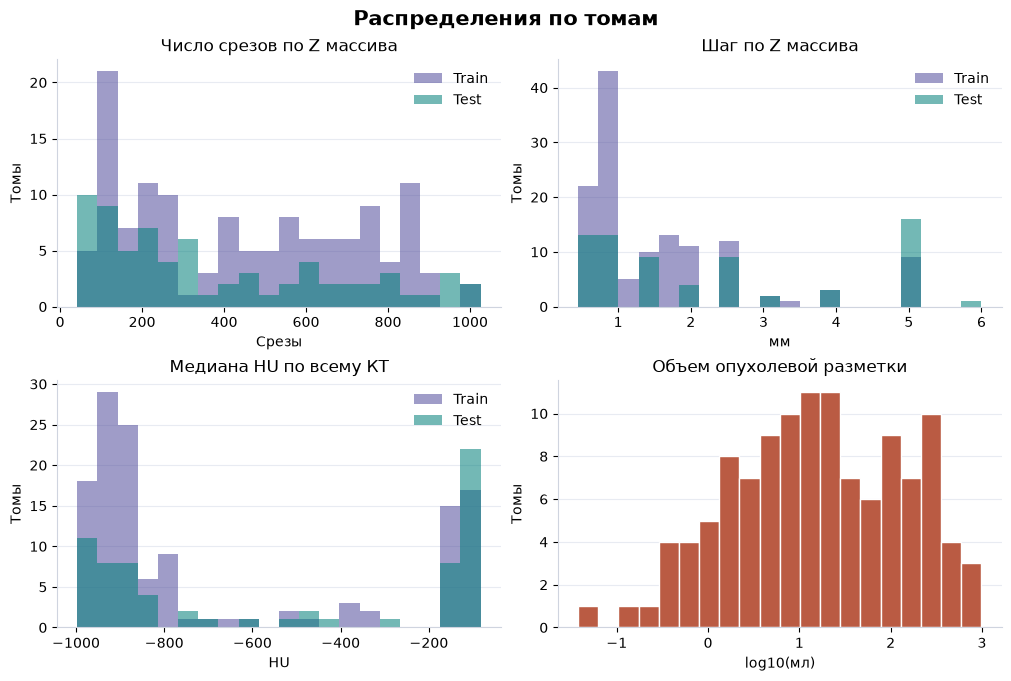

In [28]:
if not train_clean.empty or not test_clean.empty:
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.7), layout="constrained")
    fig.suptitle("Распределения по томам", fontsize=15, fontweight="bold")
    plots = [
        ("nz", "Число срезов по Z массива", "Срезы"),
        ("sz_mm", "Шаг по Z массива", "мм"),
        ("hu_median", "Медиана HU по всему КТ", "HU"),
    ]
    for ax, (column, title, xlabel) in zip(axes.flat, plots):
        values = pd.concat([train_clean[column], test_clean[column]])
        bins = np.histogram_bin_edges(values, bins=20)
        ax.hist(train_clean[column], bins=bins, color=train_color, alpha=0.55, label="Train")
        ax.hist(test_clean[column], bins=bins, color=test_color, alpha=0.55, label="Test")
        ax.set(title=title, xlabel=xlabel, ylabel="Томы")
        ax.legend(frameon=False)
        style_plot(ax)

    ax = axes[1, 1]
    tumor_ml = train_clean.loc[train_clean["tumor_ml"] > 0, "tumor_ml"]
    ax.hist(np.log10(tumor_ml), bins=20, color=tumor_color, edgecolor="white")
    ax.set(title="Объем опухолевой разметки", xlabel="log10(мл)", ylabel="Томы")
    style_plot(ax)
    plt.show()

Медиана HU по всему КТ не заменяет сравнение интенсивностей печени и опухоли. Для этого ниже используем области из масок.

### Корреляции

Смотрим линейные связи между размером тома, шагом, интенсивностью и объемом разметки. Корреляция не показывает, хорошо ли видны мелкие участки.

In [29]:
corr_cols = eda_cols + ["liver_ml", "tumor_ml"]
corr_data = train_clean[corr_cols]
corr_data = corr_data.loc[:, corr_data.nunique() > 1]
correlations = corr_data.corr()
display(correlations.round(2))

,nz,sx_mm,sy_mm,sz_mm,hu_median,liver_ml,tumor_ml
nz,1.00,0.09,0.09,-0.73,-0.09,0.04,0.14
sx_mm,0.09,1.00,1.00,0.08,-0.36,0.26,0.02
sy_mm,0.09,1.00,1.00,0.08,-0.36,0.26,0.02
sz_mm,-0.73,0.08,0.08,1.00,0.03,0.00,-0.12
hu_median,-0.09,-0.36,-0.36,0.03,1.00,0.24,0.03
liver_ml,0.04,0.26,0.26,0.00,0.24,1.00,0.54
tumor_ml,0.14,0.02,0.02,-0.12,0.03,0.54,1.00


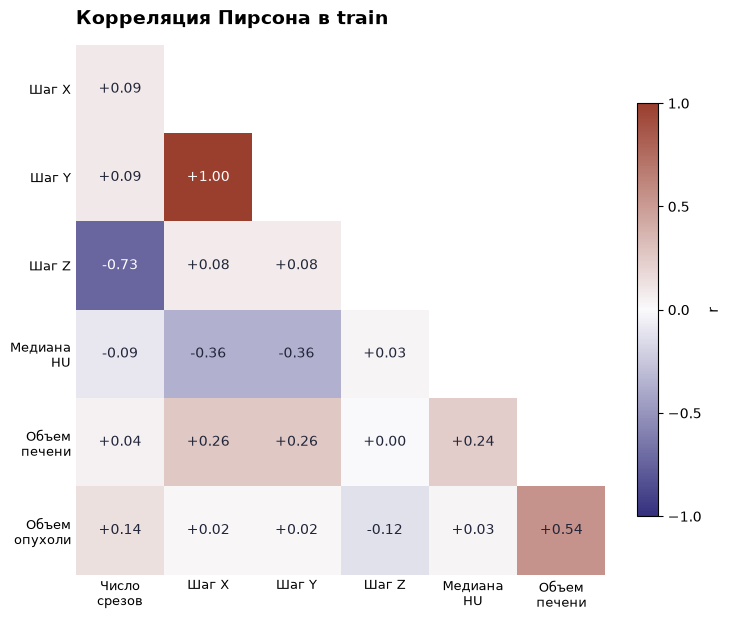

In [30]:
if len(corr_data) >= 3 and len(correlations) >= 2:
    labels = {
        "nz": "Число\nсрезов", "sx_mm": "Шаг X", "sy_mm": "Шаг Y",
        "sz_mm": "Шаг Z", "hu_median": "Медиана\nHU",
        "liver_ml": "Объем\nпечени", "tumor_ml": "Объем\nопухоли",
    }
    values = correlations.round(2).to_numpy()
    triangle = np.triu(np.ones(values.shape, dtype=bool))
    cmap = LinearSegmentedColormap.from_list("correlation", ["#34307E", "#FAFAFC", "#9A3E2E"])

    fig, ax = plt.subplots(figsize=(7.6, 6.1), layout="constrained")
    heatmap = ax.imshow(np.ma.masked_where(triangle, values), cmap=cmap, vmin=-1, vmax=1)
    positions = np.arange(len(correlations))
    names = [labels[column] for column in correlations.columns]
    ax.set_xticks(positions[:-1], names[:-1], fontsize=9)
    ax.set_yticks(positions[1:], names[1:], fontsize=9)
    ax.set_xlim(-0.5, len(values) - 1.5)
    ax.set_ylim(len(values) - 0.5, 0.5)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    for i, j in zip(*np.tril_indices(len(values), k=-1)):
        value = values[i, j]
        ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=10,
                color="white" if abs(value) > 0.63 else "#22263A")
    ax.set_title("Корреляция Пирсона в train", loc="left", pad=15, fontsize=14, fontweight="bold")
    fig.colorbar(heatmap, ax=ax, shrink=0.78, label="r", ticks=[-1, -0.5, 0, 0.5, 1])
    plt.show()

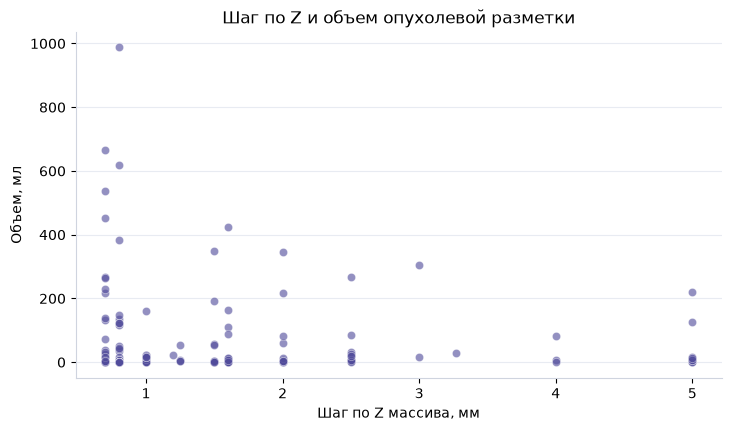

In [31]:
if not train_clean.empty:
    fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
    ax.scatter(train_clean["sz_mm"], train_clean["tumor_ml"],
               s=35, color=train_color, alpha=0.62, edgecolors="white", linewidth=0.4)
    ax.set(title="Шаг по Z и объем опухолевой разметки",
           xlabel="Шаг по Z массива, мм", ylabel="Объем, мл")
    style_plot(ax)
    plt.show()

При большем шаге по Z в томе обычно меньше срезов. Связь шага с общим объемом опухолевой разметки слабая. По этой корреляции нельзя судить о потерях мелких компонентов.

In [32]:
liver_only_ml = train_clean["liver"] * train_clean["voxel_ml"]
volume_corr = pd.Series({
    "Печень с опухолью": train_clean["liver_ml"].corr(train_clean["tumor_ml"]),
    "Печень без опухоли": liver_only_ml.corr(train_clean["tumor_ml"]),
}, name="Корреляция с объемом опухоли")
display(volume_corr.round(2))

Печень с опухолью     0.54
Печень без опухоли    0.19
Name: Корреляция с объемом опухоли, dtype: float64

Сравниваем связь с объемом печени с опухолью и без нее. В первом расчете объем опухоли входит в обе величины.

### Форма масок

Смотрим, есть ли пустые срезы внутри разметки, касания края тома или участки отдельно от основной маски. Отдельный участок не обязательно ошибка - это повод посмотреть КТ рядом с маской.

In [33]:
def boundary_faces(mask):
    total = 0
    for axis in range(3):
        sides = np.moveaxis(mask, axis, 0)
        total += int(sides[0].any()) + int(sides[-1].any())
    return total


def border_clearance(mask, grid):
    distances = []
    for axis in range(3):
        other = tuple(i for i in range(3) if i != axis)
        occupied = np.flatnonzero(mask.any(axis=other))
        if not len(occupied):
            return np.nan
        margin = min(occupied[0], mask.shape[axis] - 1 - occupied[-1])
        distances.append(margin * np.linalg.norm(grid[:, axis]))
    return min(distances)


def mask_bounds(mask):
    bounds = []
    for axis in range(3):
        other = tuple(i for i in range(3) if i != axis)
        occupied = np.flatnonzero(mask.any(axis=other))
        bounds.append(slice(occupied[0], occupied[-1] + 1))
    return tuple(bounds)

Основной считаем часть маски, в которой больше всего связанных вокселей с меткой печени.

In [34]:
def organ_components(liver, tumor, organ, axis):
    crop = mask_bounds(organ)
    components, count = label(organ[crop], structure=np.ones((3, 3, 3), dtype=bool))
    liver_ids = components[liver[crop]]
    tumor_ids = components[tumor[crop]]
    main = np.bincount(liver_ids).argmax()
    other_liver = np.count_nonzero(liver_ids != main)
    other_tumor = np.count_nonzero(tumor_ids != main)

    outside_slice = np.nan
    if other_tumor:
        detached = (components != main) & tumor[crop]
        area = np.moveaxis(detached, axis, -1).sum(axis=(0, 1))
        outside_slice = int(area.argmax() + crop[axis].start)

    return {
        "organ_components": count,
        "liver_outside_main_pct": 100 * other_liver / len(liver_ids),
        "outside_tumor_slice": outside_slice,
        "tumor_outside_main_pct": 100 * other_tumor / len(tumor_ids) if len(tumor_ids) else np.nan,
    }

In [35]:
def mask_quality(path):
    image = analysis_image(path)
    data = np.asarray(image.dataobj)
    liver = data == 1
    tumor = data == 2
    organ = liver | tumor
    axis = superior_axis(image)
    axial = np.moveaxis(organ, axis, -1).sum(axis=(0, 1))
    filled = np.flatnonzero(axial)
    gaps = np.flatnonzero(axial[filled[0]:filled[-1] + 1] == 0) + filled[0]

    row = {
        "case": path.name.removesuffix(".nii.gz"),
        "shape": str(data.shape),
        "mask_hash": voxel_hash(data),
        "qform_sform_mm": header_difference(nib.load(path)),
        "liver_boundary_faces": boundary_faces(liver),
        "tumor_boundary_faces": boundary_faces(tumor),
        "tumor_edge_clearance_mm": border_clearance(tumor, affine_mm(image)),
        "axial_gaps": len(gaps),
        "first_gap": int(gaps[0]) if len(gaps) else np.nan,
    }
    row.update(organ_components(liver, tumor, organ, axis))
    return row, axial

In [36]:
qc_rows = []
area_curves = {}

for case in train_clean["case"]:
    row, axial = mask_quality(root / "labelsTr" / f"{case}.nii.gz")
    qc_rows.append(row)
    if row["axial_gaps"]:
        area_curves[case] = axial

mask_qc = pd.DataFrame(qc_rows)

In [37]:
if not mask_qc.empty:
    flags = mask_qc[["axial_gaps", "liver_boundary_faces", "tumor_boundary_faces",
                     "liver_outside_main_pct", "tumor_outside_main_pct"]].gt(0)
    display(flags.sum().rename("Томы с флагом"))
    mask_duplicates = mask_qc.duplicated(["shape", "mask_hash"], keep=False)
    if mask_duplicates.any():
        display(mask_qc.loc[mask_duplicates, ["case", "shape"]])
    display(mask_qc["qform_sform_mm"].describe().round(4))
    with_tumor = mask_qc.dropna(subset=["tumor_edge_clearance_mm"])
    closest = with_tumor.nsmallest(5, "tumor_edge_clearance_mm")
    display(closest[["case", "tumor_edge_clearance_mm"]])
    display(mask_qc.loc[flags.any(axis=1), ["case", "axial_gaps", "first_gap",
                                          "liver_outside_main_pct", "tumor_outside_main_pct"]].round(5))

axial_gaps                 2
liver_boundary_faces       0
tumor_boundary_faces       0
liver_outside_main_pct    22
tumor_outside_main_pct     2
Name: Томы с флагом, dtype: int64

count    131.0000
mean       0.0002
std        0.0002
min        0.0000
25%        0.0000
50%        0.0002
75%        0.0004
max        0.0012
Name: qform_sform_mm, dtype: float64

,case,tumor_edge_clearance_mm
52,liver_28,8.0
70,liver_44,8.0
64,liver_39,9.0
0,liver_0,10.0
129,liver_98,11.2


,case,axial_gaps,first_gap,liver_outside_main_pct,tumor_outside_main_pct
1,liver_1,0,NaN,0.01491,0.00000
2,liver_10,0,NaN,0.00003,0.00000
5,liver_102,47,325.0,0.00229,0.00000
34,liver_129,0,NaN,0.00001,0.00000
37,liver_14,0,NaN,0.00201,0.00000
39,liver_16,0,NaN,0.00088,0.00000
41,liver_18,0,NaN,0.00036,0.00000
43,liver_2,0,NaN,0.05037,0.00000
48,liver_24,0,NaN,0.00005,0.00000
51,liver_27,0,NaN,0.00000,0.06285


Пустые срезы внутри разметки нашли у liver_102 и liver_94. Отделенные участки опухолевой маски нашли у liver_27 и liver_79. Эти случаи смотрим отдельно, но не удаляем только по флагу.

### Примеры на КТ

Сверху КТ без разметки, снизу те же срезы с маской. Зеленый цвет обозначает печень, красный обозначает опухоль.

In [38]:
def plot_review_slices(ct_image, mask_image, indices, case):
    axis = superior_axis(mask_image)
    first = min(indices)
    region = [slice(None)] * 3
    region[axis] = slice(first, max(indices) + 1)
    region = tuple(region)
    mask = np.asarray(mask_image.dataobj[region])
    ct = np.asarray(ct_image.dataobj[region], dtype=np.float32)
    in_plane = [i for i in range(3) if i != axis]
    spacing = np.linalg.norm(affine_mm(ct_image)[:, in_plane], axis=0)
    fig, axes = plt.subplots(2, len(indices), figsize=(3.2 * len(indices), 6),
                             squeeze=False, layout="constrained")
    for j, z in enumerate(indices):
        image_slice = np.take(ct, z - first, axis=axis).T
        labels = np.take(mask, z - first, axis=axis).T
        for ax in axes[:, j]:
            ax.imshow(image_slice, cmap="gray", vmin=-100, vmax=200,
                      origin="lower", aspect=spacing[1] / spacing[0])
            ax.axis("off")
        for value, cmap in [(1, "Greens"), (2, "Reds")]:
            overlay = np.ma.masked_where(labels != value, np.ones(labels.shape))
            axes[1, j].imshow(overlay, cmap=cmap, vmin=0, vmax=1, alpha=0.55,
                              origin="lower", aspect=spacing[1] / spacing[0])
        axes[0, j].set_title(f"Срез {z}")
        axes[1, j].set_title("КТ + маска")
    fig.suptitle(case)
    plt.show()

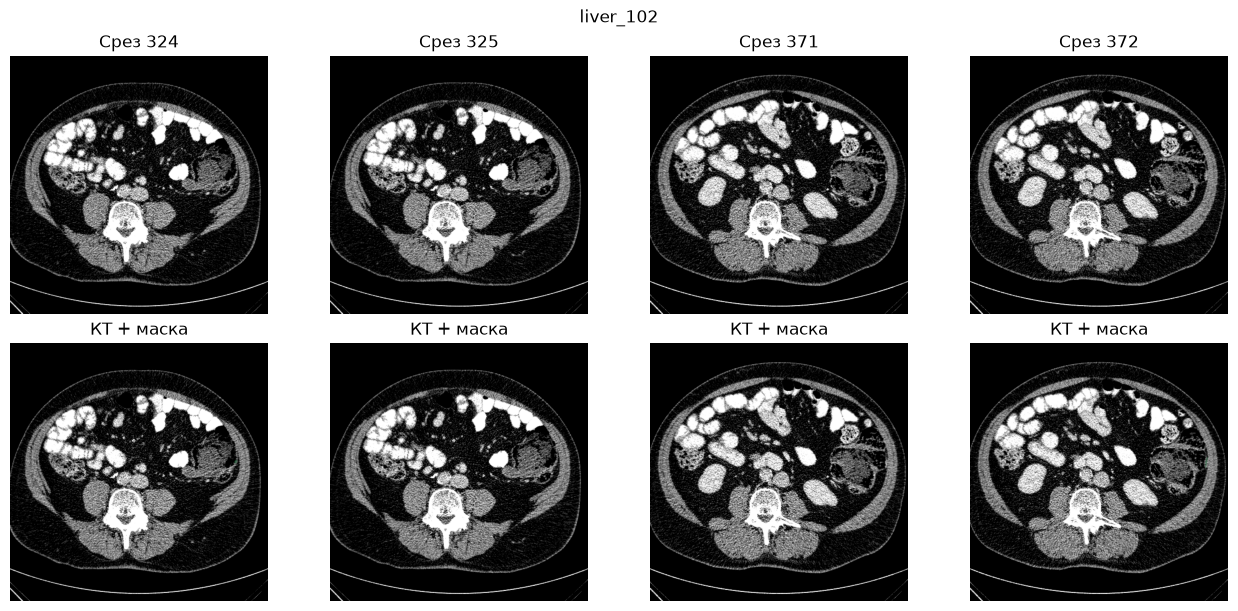

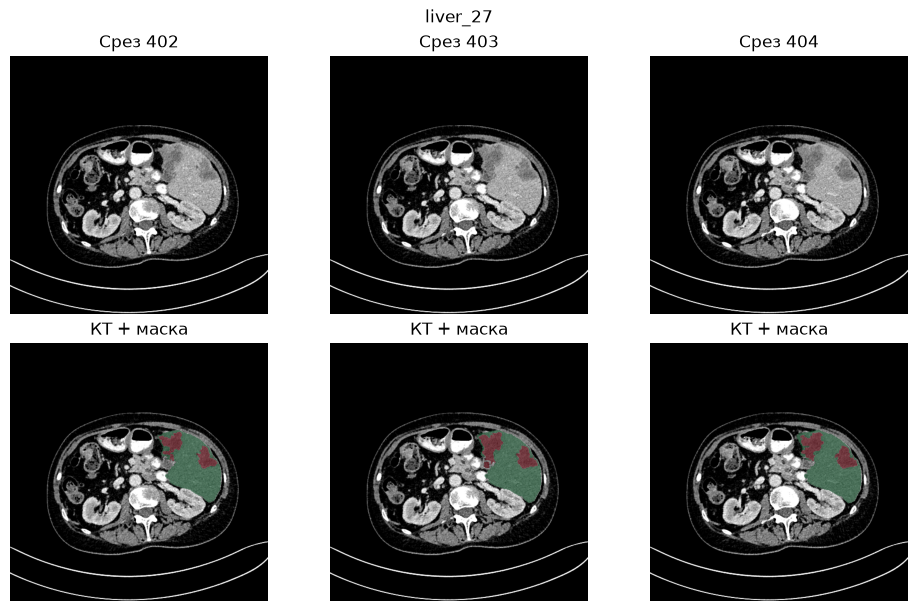

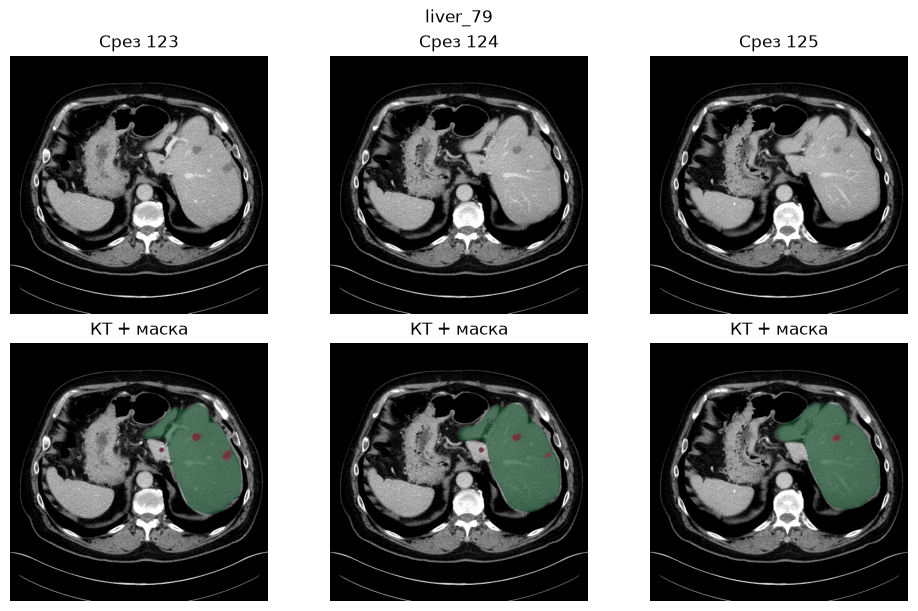

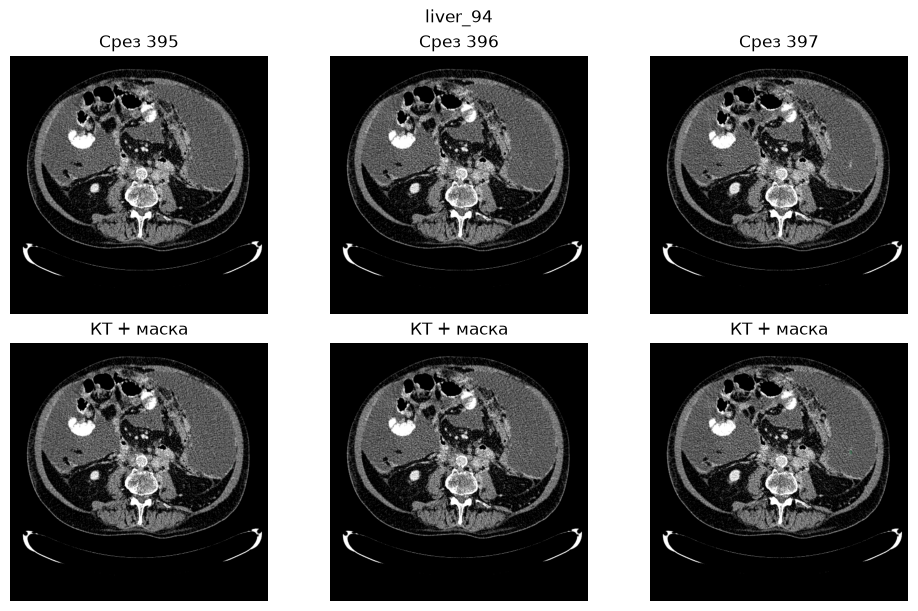

In [39]:
review_rows = []
if not mask_qc.empty:
    flagged = mask_qc[(mask_qc["axial_gaps"] > 0) | (mask_qc["tumor_outside_main_pct"] > 0)]
    for row in flagged.itertuples(index=False):
        case = row.case
        name = f"{case}.nii.gz"
        ct_image = analysis_image(root / "imagesTr" / name)
        mask_image = analysis_image(root / "labelsTr" / name)
        axis = superior_axis(mask_image)

        if row.axial_gaps:
            occupied = np.flatnonzero(area_curves[case])
            gap = np.diff(occupied).argmax()
            left, right = occupied[gap:gap + 2]
            indices = sorted({int(left), int(left + 1), int(right - 1), int(right)})
            plot_review_slices(ct_image, mask_image, indices, case)
            review_rows.append({"case": case, "reason": "Разрыв", "slices": indices})

        if pd.notna(row.outside_tumor_slice):
            z = int(row.outside_tumor_slice)
            indices = [i for i in (z - 1, z, z + 1) if 0 <= i < mask_image.shape[axis]]
            plot_review_slices(ct_image, mask_image, indices, case)
            review_rows.append({"case": case, "reason": "Отделенная метка", "slices": indices})

ct_review_slices = pd.DataFrame(review_rows, columns=["case", "reason", "slices"])

### Размер опухолевых участков

Компонентом считаем группу соседних вокселей с меткой опухоли. Один компонент не обязательно равен одному клиническому очагу. Сравниваем подсчет по 6 соседям (соприкосновение по грани) и по 26 соседям (также по ребру и углу). Размер и покрытие отдельных компонентов дальше считаем по 26 соседям.

В [LiTS](https://doi.org/10.1016/j.media.2022.102680) совпадение масок и обнаружение опухолей оценивали отдельно. Хорошее совпадение масок само по себе не означает, что найдены все мелкие очаги.

In [40]:
def tumor_components(tumor, case, voxel_ml):
    crop = mask_bounds(tumor)
    tumor = tumor[crop].copy()
    count_6 = label(tumor)[1]
    labels, count_26 = label(tumor, structure=np.ones((3, 3, 3), dtype=bool))
    counts = np.bincount(labels[tumor])
    objects = []
    for component, bounds in enumerate(find_objects(labels), start=1):
        voxels = int(counts[component])
        slices = bounds[2].stop - bounds[2].start
        objects.append({
            "case": case,
            "component": component,
            "voxels": voxels,
            "volume_ml": voxels * voxel_ml,
            "slices": slices,
            "z_first": int(crop[2].start + bounds[2].start),
            "z_last": int(crop[2].start + bounds[2].stop - 1),
        })
    return count_6, count_26, objects

In [41]:
def count_slices(mask):
    liver = mask == 1
    liver_voxels = np.count_nonzero(liver)
    liver_slices = liver.any(axis=(0, 1))
    del liver
    tumor = mask == 2
    tumor_voxels = np.count_nonzero(tumor)
    tumor_slices = tumor.any(axis=(0, 1))
    positive = np.count_nonzero(tumor_slices)
    liver_only = np.count_nonzero(liver_slices & ~tumor_slices)
    return liver_voxels, tumor_voxels, positive, liver_only, tumor

In [42]:
def mask_profile(mask_path):
    image = analysis_image(mask_path)
    axis = superior_axis(image)
    grid = affine_mm(image)
    spacing = np.linalg.norm(grid[:, axis])
    voxel_ml = abs(np.linalg.det(grid[:, :3])) / 1000
    mask = np.moveaxis(np.asarray(image.dataobj), axis, -1)
    liver_voxels, tumor_voxels, positive, liver_only, tumor = count_slices(mask)
    row = {
        "case": mask_path.name.removesuffix(".nii.gz"),
        "z_mm": spacing,
        "all_slices": mask.shape[-1],
        "tumor_slices": positive,
        "liver_only_slices": liver_only,
        "neither_slices": mask.shape[-1] - positive - liver_only,
        "tumor_ml": tumor_voxels * voxel_ml,
        "tumor_pct_ct": 100 * tumor_voxels / mask.size,
        "tumor_pct_liver": 100 * tumor_voxels / (liver_voxels + tumor_voxels),
        "components_6": 0,
        "components_26": 0,
        "one_voxel_26": 0,
        "one_slice_26": 0,
    }
    del mask
    if not tumor_voxels:
        return row, []

    count_6, count_26, objects = tumor_components(tumor, row["case"], voxel_ml)
    row["components_6"] = count_6
    row["components_26"] = count_26
    row["one_voxel_26"] = sum(obj["voxels"] == 1 for obj in objects)
    row["one_slice_26"] = sum(obj["slices"] == 1 for obj in objects)
    return row, objects

In [43]:
def sampling_table(profiles):
    all_slices = profiles["all_slices"]
    liver_slices = profiles["tumor_slices"] + profiles["liver_only_slices"]
    positives = profiles["tumor_slices"]
    rows = []
    for name, pool in [("Все срезы", all_slices), ("Срезы с печенью или опухолью", liver_slices)]:
        eligible = pool > 0
        total = pool.sum()
        rows.append({
            "pool": name,
            "cases": int(eligible.sum()),
            "slices": int(total),
            "positive_pct_pooled": 100 * positives.sum() / total,
            "positive_pct_equal_case": 100 * (positives[eligible] / pool[eligible]).mean(),
            "top_10_cases_pct": 100 * pool.nlargest(10).sum() / total,
        })
    return pd.DataFrame(rows)

In [44]:
def component_sensitivity(components):
    rows = []
    total = len(components)
    total_ml = components["volume_ml"].sum()
    for name, subset in [
        ("Все: 26 соседей", components),
        ("Без одновоксельных: 26 соседей", components[components["voxels"] > 1]),
        ("Только на одном срезе", components[components["slices"] == 1]),
        ("Меньше 1 мл", components[components["volume_ml"] < 1]),
    ]:
        volume_ml = subset["volume_ml"].sum()
        rows.append({
            "definition": name,
            "n_components": len(subset),
            "share_of_components_pct": 100 * len(subset) / total if total else np.nan,
            "share_of_volume_pct": 100 * volume_ml / total_ml if total_ml else np.nan,
            "cases": subset["case"].nunique(),
        })
    return pd.DataFrame(rows)

### Результаты по компонентам

In [45]:
profile_rows = []
component_rows = []
for case in train_clean["case"]:
    row, objects = mask_profile(root / "labelsTr" / f"{case}.nii.gz")
    profile_rows.append(row)
    component_rows.extend(objects)

profiles = pd.DataFrame(profile_rows)
mask_review = pd.DataFrame()
components = pd.DataFrame(component_rows, columns=["case", "component", "voxels", "volume_ml", "slices", "z_first", "z_last"])
if not profiles.empty:
    display(profiles[["components_6", "components_26"]].sum().to_frame("Компоненты"))
    display(component_sensitivity(components).round(3))
    mask_review = profiles[["case", "components_6", "components_26", "one_voxel_26", "one_slice_26"]].copy()
    mask_review["change_with_connectivity"] = mask_review["components_6"] - mask_review["components_26"]
    mask_review = mask_review.sort_values(["change_with_connectivity", "one_voxel_26", "components_26"], ascending=False)
    display(mask_review.head(8))

,Компоненты
components_6,1037
components_26,908


,definition,n_components,share_of_components_pct,share_of_volume_pct,cases
0,Все: 26 соседей,908,100.000,100.000,118
1,Без одновоксельных: 26 соседей,890,98.018,100.000,118
2,Только на одном срезе,78,8.590,0.061,26
3,Меньше 1 мл,559,61.564,1.637,86


,case,components_6,components_26,one_voxel_26,one_slice_26,change_with_connectivity
17,liver_113,65,29,5,9,36
65,liver_4,34,5,0,0,29
27,liver_122,24,17,2,2,7
127,liver_96,29,23,0,0,6
11,liver_108,70,66,1,3,4
21,liver_117,79,75,0,1,4
7,liver_104,10,6,0,0,4
4,liver_101,20,17,7,8,3


При учете касаний по диагонали часть компонентов объединяется. Компоненты меньше 1 мл составляют большинство по числу, но малую долю объема. Поэтому проверяем их отдельно, а не только через общий Dice.

### Доля срезов с опухолью

In [46]:
sampling = pd.DataFrame()
if not profiles.empty:
    sampling = sampling_table(profiles)
    display(sampling.round(2))

,pool,cases,slices,positive_pct_pooled,positive_pct_equal_case,top_10_cases_pct
0,Все срезы,131,58638,12.26,13.27,15.30
1,Срезы с печенью или опухолью,131,19163,37.52,34.88,14.34


Среди срезов с печенью или опухолью опухолевая метка встречается чаще, чем среди всех срезов. Это аргумент за проверку отбора срезов. На новых КТ готовой маски печени не будет.

### HU печени и опухоли

На каждом КТ с опухолевой меткой сравниваем медианы HU в двух областях: в печени без опухолевой разметки и внутри опухолевой маски. Смотрим и разницу медиан, и долю вокселей за пределами двух диапазонов: от -100 до 200 HU и от -50 до 150 HU. Это варианты для предобработки.

КТ с парным сравнением     118
Медиана HU опухоли выше      3
Name: Значение, dtype: int64

,count,mean,std,min,25%,50%,75%,max
liver_hu_median,118.0,101.28,19.99,27.00,90.75,99.50,114.00,165.00
tumor_hu_median,118.0,64.81,20.96,8.00,49.25,67.00,78.75,138.00
liver_clipped_wide_pct,118.0,0.48,0.94,0.00,0.05,0.15,0.56,7.12
tumor_clipped_wide_pct,118.0,0.08,0.33,0.00,0.00,0.00,0.04,3.27
liver_clipped_narrow_pct,118.0,6.59,9.95,0.06,1.29,2.95,7.82,75.10
tumor_clipped_narrow_pct,118.0,1.18,3.17,0.00,0.03,0.24,1.02,30.94
tumor_minus_liver_hu,118.0,-36.47,21.85,-102.00,-48.75,-34.50,-22.25,44.00


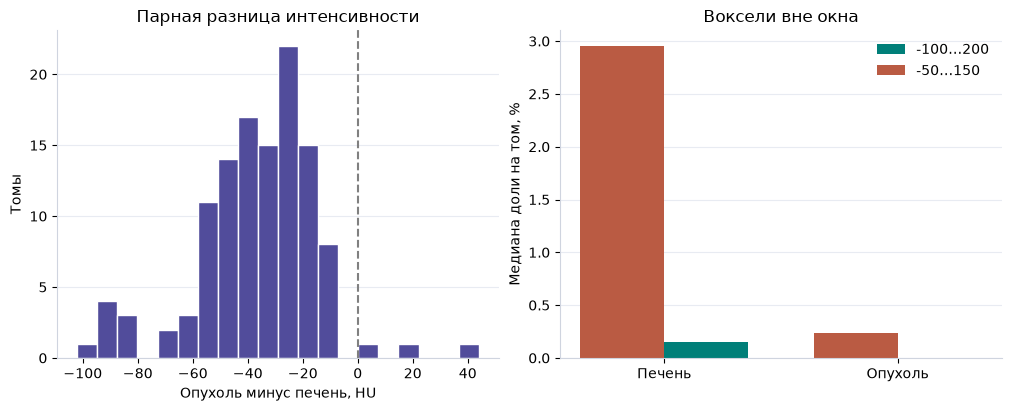

In [47]:
train = usable[usable["split"] == "train"]
contrast_columns = ["liver_hu_median", "tumor_hu_median", "liver_clipped_wide_pct",
                    "tumor_clipped_wide_pct", "liver_clipped_narrow_pct", "tumor_clipped_narrow_pct"]
contrast = train[["case"] + contrast_columns].dropna(subset=["tumor_hu_median"]).copy()
contrast["tumor_minus_liver_hu"] = contrast["tumor_hu_median"] - contrast["liver_hu_median"]

if not contrast.empty:
    display(pd.Series({
        "КТ с парным сравнением": len(contrast),
        "Медиана HU опухоли выше": contrast["tumor_minus_liver_hu"].gt(0).sum(),
    }, name="Значение"))
    display(contrast[contrast_columns + ["tumor_minus_liver_hu"]].describe().T.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    axes[0].hist(contrast["tumor_minus_liver_hu"], bins=20, color=train_color, edgecolor="white")
    axes[0].axvline(0, color="gray", linestyle="--")
    axes[0].set(title="Парная разница интенсивности", xlabel="Опухоль минус печень, HU", ylabel="Томы")
    clipped = contrast[contrast_columns[2:]].median()
    axes[1].bar(["Печень", "Опухоль"], clipped.iloc[:2], width=0.36, align="edge", label="-100…200", color=test_color)
    axes[1].bar(["Печень", "Опухоль"], clipped.iloc[2:], width=-0.36, align="edge", label="-50…150", color=tumor_color)
    axes[1].set(title="Воксели вне окна", ylabel="Медиана доли на том, %")
    axes[1].legend(frameon=False)
    for ax in axes:
        style_plot(ax)
    plt.show()

В большинстве размеченных КТ медиана HU внутри опухолевой маски ниже, чем в остальной печени. На отдельных КТ разница меняет знак. 

### Где узкое окно HU обрезает больше значений

Для каждого КТ вычитаем долю опухолевых вокселей вне широкого окна из доли вне узкого. Так видно, сколько значений дополнительно попадет под обрезку при сужении окна.

КТ                       118.00
Медиана разницы, п.п.      0.24
Name: Значение, dtype: float64

,"Широкое, %","Узкое, %","Разница, п.п."
КТ,,,
liver_35,0.97,30.94,29.97
liver_85,0.91,10.49,9.57
liver_39,0.00,4.62,4.62
liver_99,0.28,4.87,4.59
liver_43,0.20,4.67,4.47
liver_103,0.17,4.52,4.35


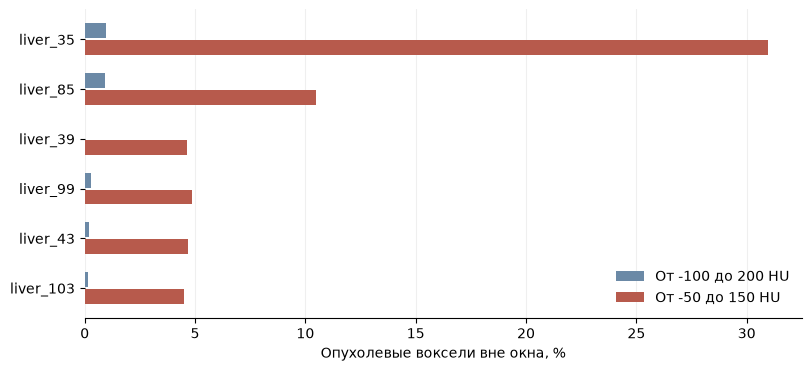

In [48]:
wide = "tumor_clipped_wide_pct"
narrow = "tumor_clipped_narrow_pct"
windows = contrast[["case", wide, narrow]].copy()
windows["extra_pp"] = windows[narrow] - windows[wide]
display(pd.Series({
    "КТ": len(windows),
    "Медиана разницы, п.п.": round(windows["extra_pp"].median(), 2),
}, name="Значение"))
top_windows = windows.nlargest(6, "extra_pp").set_index("case")[[wide, narrow, "extra_pp"]]
top_windows.index.name = "КТ"
top_windows.columns = ["Широкое, %", "Узкое, %", "Разница, п.п."]
display(top_windows.round(2))

fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
positions = range(len(top_windows))
ax.barh([i - 0.17 for i in positions], top_windows["Широкое, %"], height=0.30,
        color="#6B89A6", label="От -100 до 200 HU")
ax.barh([i + 0.17 for i in positions], top_windows["Узкое, %"], height=0.30,
        color="#B75A4C", label="От -50 до 150 HU")
ax.set_yticks(list(positions), top_windows.index)
ax.invert_yaxis()
ax.set_xlabel("Опухолевые воксели вне окна, %")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

В типичном томе сужение окна мало меняет долю обрезанных опухолевых вокселей. Но у liver_35 и liver_85 разница заметна. Для первого сравнения берем широкое окно и не меняем его между запусками.

## Что меняется при подготовке данных

### Ресемплинг масок

Отталкиваемся от сетки 0,8 × 0,8 × 1 мм. В одном варианте меняем только Z (1 на 2 мм), в другом только X/Y (0,8 на 0,7 мм). Все три варианта строим из одной исходной маски, а не друг из друга.

Номера компонентов переносим методом ближайшего соседа. Начало новой сетки привязываем к краю исходного тома. Если на новой сетке нет ни одного вокселя с исходным номером, компонент потерян.

In [49]:
def nearest_indices(size, ratio):
    return np.floor((np.arange(size) + 0.5) * ratio).astype(int)


def count_on_target(labels, bounds, forward, n):
    indices = [axis[(axis >= crop.start) & (axis < crop.stop)] - crop.start
               for axis, crop in zip(forward, bounds)]
    x, y, z = indices
    counts = np.zeros(n + 1, dtype=np.int64)
    for start in range(0, len(z), 16):
        block = labels[np.ix_(x, y, z[start:start + 16])]
        counts += np.bincount(block.ravel(), minlength=n + 1)
    return counts[1:]

Dice после переноса туда и обратно сравнивает исходную маску с восстановленной на исходной сетке. Он показывает изменение маски от ресемплинга, а не качество модели. Отдельно считаем изменение объема и потерянные компоненты, высокий Dice может скрывать потерю мелких участков.

In [50]:
def mask_roundtrip(tumor, labels, bounds, forward, ratios, before):
    original, restored = [], []
    for size, crop, axis, ratio in zip(tumor.shape, bounds, forward, ratios):
        target = nearest_indices(size, 1 / ratio)
        source = np.full(size, -1)
        valid = (target >= 0) & (target < len(axis))
        source[valid] = axis[target[valid]]
        keep = (source >= crop.start) & (source < crop.stop)
        original.append(np.flatnonzero(keep))
        restored.append(source[keep] - crop.start)

    x, y, z = original
    xx, yy, zz = restored
    intersection, recovered = 0, 0
    for start in range(0, len(z), 16):
        block = slice(start, start + 16)
        mask_back = labels[np.ix_(xx, yy, zz[block])] > 0
        mask_start = tumor[np.ix_(x, y, z[block])]
        recovered += np.count_nonzero(mask_back)
        intersection += np.count_nonzero(mask_start & mask_back)
    return 2 * intersection / (before + recovered)

In [51]:
def compare_mask_steps(mask_path, targets):
    image = nib.as_closest_canonical(analysis_image(mask_path))
    tumor = np.asarray(image.dataobj) == 2
    if not tumor.any():
        return [], []

    case = mask_path.name.removesuffix(".nii.gz")
    bounds = mask_bounds(tumor)
    labels, n = label(tumor[bounds], structure=np.ones((3, 3, 3), dtype=bool))
    before = np.bincount(labels.ravel(), minlength=n + 1)[1:]
    grid = affine_mm(image)[:, :3]
    spacing = np.linalg.norm(grid, axis=0)
    voxel_ml = abs(np.linalg.det(grid)) / 1000
    before_ml = before * voxel_ml

    components, summary = [], []
    for name, target in targets.items():
        ratios = np.array(target) / spacing
        size = np.maximum(1, np.ceil(np.round(np.array(image.shape) / ratios, 7)).astype(int))
        forward = [nearest_indices(length, ratio) for length, ratio in zip(size, ratios)]
        after = count_on_target(labels, bounds, forward, n)
        after_ml = after * voxel_ml * np.prod(ratios)
        components.append(pd.DataFrame({
            "case": case, "step": name, "component": np.arange(1, n + 1),
            "before_ml": before_ml, "after_ml": after_ml,
        }))
        summary.append({
            "case": case, "step": name, "geometry_pending": case in unresolved,
            "lost": np.count_nonzero(after == 0),
            "dice_roundtrip": mask_roundtrip(tumor, labels, bounds, forward, ratios, before.sum()),
            "abs_volume_change_pct": 100 * abs(after_ml.sum() / before_ml.sum() - 1),
            "grid_ratio": np.prod(size) / np.prod(image.shape),
        })
    return components, summary

In [52]:
targets = {
    "0,8 × 0,8 × 1": (0.8, 0.8, 1),
    "0,8 × 0,8 × 2": (0.8, 0.8, 2),
    "0,7 × 0,7 × 1": (0.7, 0.7, 1),
}

step_rows = []
case_metrics = []
for case in train_clean.loc[train_clean["tumor"] > 0, "case"]:
    rows, metrics = compare_mask_steps(root / "labelsTr" / f"{case}.nii.gz", targets)
    step_rows.extend(rows)
    case_metrics.extend(metrics)

step_columns = ["case", "step", "component", "before_ml", "after_ml"]
step_components = pd.concat(step_rows, ignore_index=True) if step_rows else pd.DataFrame(columns=step_columns)
step_components["lost"] = step_components["after_ml"].eq(0)
step_components["size"] = pd.cut(
    step_components["before_ml"], bins=[0, 0.1, 1, np.inf], right=False,
    labels=["Меньше 0,1 мл", "От 0,1 до 1 мл", "От 1 мл"],
)
step_components["volume_change_pct"] = (
    100 * (step_components["after_ml"] / step_components["before_ml"] - 1).abs()
).where(~step_components["lost"])

resampling_cases = pd.DataFrame(case_metrics, columns=[
    "case", "step", "geometry_pending", "lost", "dice_roundtrip", "abs_volume_change_pct", "grid_ratio",
])

In [53]:
step_summary = step_components.groupby(["step", "size"], sort=False, observed=True).agg(
    components=("lost", "size"),
    lost=("lost", "sum"),
    median_change_pct=("volume_change_pct", "median"),
)
step_summary["lost_pct"] = 100 * step_summary["lost"] / step_summary["components"]
step_summary = step_summary[["components", "lost", "lost_pct", "median_change_pct"]]
step_summary.index.names = ["Шаг, мм", "Исходный объем"]
step_summary.columns = [
    "Компонентов", "Потеряно", "Потеряно, %", "Медиана изменения объема, %"
]
display(step_summary.round(2))

total_losses = resampling_cases.groupby("step", sort=False).agg(
    cases=("case", "size"),
    lost_components=("lost", "sum"),
    affected_cases=("lost", lambda counts: counts.gt(0).sum()),
    dice_median=("dice_roundtrip", "median"),
    volume_error_p95=("abs_volume_change_pct", lambda values: values.quantile(0.95)),
    grid_ratio_median=("grid_ratio", "median"),
)
total_losses.index.name = "Шаг, мм"
total_losses.columns = [
    "КТ с опухолевой меткой", "Потеряно компонентов", "КТ с потерями",
    "Dice, медиана", "Ошибка объема, p95, %", "Отношение размера сетки, медиана",
]
display(total_losses.round(3))

Компонентов  Потеряно  Потеряно, %  \
Шаг, мм       Исходный объем                                       
0,8 × 0,8 × 1 От 0,1 до 1 мл          406         0         0.00   
              От 1 мл                 349         0         0.00   
0,8 × 0,8 × 2 От 0,1 до 1 мл          406         0         0.00   
              От 1 мл                 349         0         0.00   
0,7 × 0,7 × 1 От 0,1 до 1 мл          406         0         0.00   
              От 1 мл                 349         0         0.00   
0,8 × 0,8 × 1 Меньше 0,1 мл           153        12         7.84   
0,8 × 0,8 × 2 Меньше 0,1 мл           153        28        18.30   
0,7 × 0,7 × 1 Меньше 0,1 мл           153        11         7.19   

                              Медиана изменения объема, %  
Шаг, мм       Исходный объем                               
0,8 × 0,8 × 1 От 0,1 до 1 мл                         3.90  
              От 1 мл                                0.66  
0,8 × 0,8 × 2 От 0,1 до 1 мл                         6.32  
              От 1 мл                                1.06  
0,7 × 0,7 × 1 От 0,1 до 1 мл                         4.07  
              От 1 мл                                0.74  
0,8 × 0,8 × 1 Меньше 0,1 мл                         15.71  
0,8 × 0,8 × 2 Меньше 0,1 мл                         22.05  
0,7 × 0,7 × 1 Меньше 0,1 мл                         12.63

,КТ с опухолевой меткой,Потеряно компонентов,КТ с потерями,"Dice, медиана","Ошибка объема, p95, %","Отношение размера сетки, медиана"
"Шаг, мм",,,,,,
"0,8 × 0,8 × 1",118,12,7,0.987,3.536,1.027
"0,8 × 0,8 × 2",118,28,11,0.964,6.365,0.514
"0,7 × 0,7 × 1",118,11,6,0.997,5.013,1.343


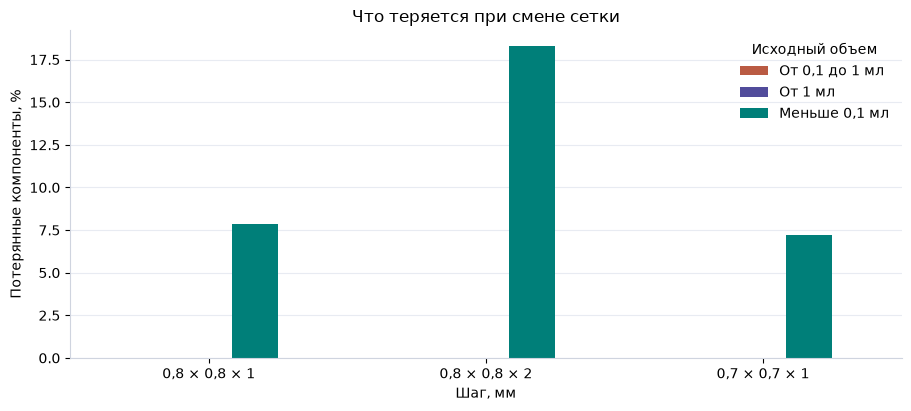

In [54]:
if not step_summary.empty:
    losses = step_summary["Потеряно, %"].unstack()
    losses = losses.reindex(targets)
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    losses.plot.bar(ax=ax, rot=0, color=[tumor_color, train_color, test_color][:len(losses.columns)])
    ax.set(title="Что теряется при смене сетки", xlabel="Шаг, мм", ylabel="Потерянные компоненты, %")
    ax.legend(title="Исходный объем", frameon=False)
    style_plot(ax)
    plt.show()

При увеличении шага Z до 2 мм теряется больше компонентов, чем при 1 мм. Во всех трех вариантах полностью исчезали только компоненты меньше 0,1 мл.

При уменьшении шага X/Y до 0,7 мм Dice после переноса туда и обратно выше, но сохранился всего на один компонент больше. Сетка стала крупнее, а ошибка объема на 95-м процентиле выросла. Поэтому начинаем с 0,8 × 0,8 × 1 мм. Это отправная точка для модели.

Изменение объема отдельного компонента считаем по модулю среди сохранившихся компонентов. В ошибку общего объема на КТ входят и полные потери.

### Сводка без КТ с неподтвержденным шагом

Дополнительная сводка выводится, только если остались КТ с неподтвержденной геометрией. В этом запуске все 20 сопоставлений подтверждены, поэтому отдельной таблицы нет.

In [55]:
loss_sensitivity = pd.DataFrame()
if unresolved and not step_components.empty:
    verified_subset = step_components.loc[~step_components["case"].isin(unresolved)]
    rows = []
    for name, group in [("Все доступные КТ", step_components),
                        ("Без КТ с непроверенным шагом 1 мм", verified_subset)]:
        counts = group.groupby("step", sort=False).agg(
            cases=("case", "nunique"), components=("lost", "size"), lost=("lost", "sum")
        ).reindex(targets, fill_value=0)
        counts["КТ в сводке"] = name
        counts["Потеряно, %"] = 100 * counts["lost"] / counts["components"].replace(0, np.nan)
        rows.append(counts.reset_index())
    loss_sensitivity = pd.concat(rows, ignore_index=True)
    loss_sensitivity = loss_sensitivity.rename(columns={
        "step": "Шаг, мм", "cases": "КТ с опухолевой меткой",
        "components": "Компонентов", "lost": "Потеряно",
    })
    display(loss_sensitivity.round(2))

### Отбор срезов на исходных масках

Сравниваем случайный отбор, 50/50 срезов с опухолью и без нее, и 50/50 с весами по томам. В третьем варианте внутри каждой группы срезы из томов, где таких срезов меньше, получают больший вес. Для каждого варианта отбираем по 1000 разных срезов и повторяем отбор 50 раз.

Компонент засчитываем, если в выборку попал хотя бы один его срез. Показываем медиану и разброс между повторами по 10-му и 90-му процентилям.

In [56]:
def slice_pools(profiles, components):
    profiles = profiles.sort_values("case").reset_index(drop=True)
    lengths = profiles["all_slices"].to_numpy(dtype=int)
    offsets = np.r_[0, np.cumsum(lengths)[:-1]]
    first_slice = pd.Series(offsets, index=profiles["case"])
    component_offsets = components["case"].map(first_slice).to_numpy(dtype=int)
    starts = component_offsets + components["z_first"].to_numpy(dtype=int)
    ends = component_offsets + components["z_last"].to_numpy(dtype=int)
    cases_by_slice = np.repeat(np.arange(len(profiles)), lengths)
    positive = np.zeros(len(cases_by_slice), dtype=bool)
    for start, end in zip(starts, ends):
        positive[start:end + 1] = True
    return starts, ends, cases_by_slice, positive


def case_weights(pool, cases_by_slice, n_cases):
    owners = cases_by_slice[pool]
    weights = 1 / np.bincount(owners, minlength=n_cases)[owners]
    return weights / weights.sum() if len(weights) else None

In [57]:
def slice_samples(profiles, cases_by_slice, positive, requested_budget, repeats):
    pos = np.flatnonzero(positive)
    neg = np.flatnonzero(~positive)
    budget = min(requested_budget, len(positive))
    n_pos = max(budget - len(neg), min(budget // 2, len(pos)))
    n_neg = budget - n_pos
    pos_weights = case_weights(pos, cases_by_slice, len(profiles))
    neg_weights = case_weights(neg, cases_by_slice, len(profiles))

    rng = np.random.default_rng(42)
    for repeat in range(1, repeats + 1):
        yield "Равномерно", repeat, rng.choice(len(positive), budget, replace=False)
        for method in ("50/50", "50/50 с балансом томов"):
            by_case = method != "50/50"
            picked = np.r_[
                rng.choice(pos, n_pos, replace=False, p=pos_weights if by_case else None),
                rng.choice(neg, n_neg, replace=False, p=neg_weights if by_case else None),
            ]
            yield method, repeat, picked

In [58]:
def compare_slice_sampling(profiles, components, requested_budget=1000, repeats=50):
    starts, ends, cases_by_slice, positive = slice_pools(profiles, components)
    groups = {
        "Все": np.ones(len(components), dtype=bool),
        "<1 мл": components["volume_ml"].to_numpy() < 1,
        "Один срез": components["slices"].to_numpy() == 1,
    }

    rows = []
    for method, repeat, picked in slice_samples(profiles, cases_by_slice, positive, requested_budget, repeats):
        selected = np.zeros(len(positive), dtype=bool)
        selected[picked] = True
        seen = np.array([selected[start:end + 1].any() for start, end in zip(starts, ends)])
        for group, group_mask in groups.items():
            available = int(group_mask.sum())
            if not available:
                continue
            found = int(np.count_nonzero(seen & group_mask))
            rows.append({
                "method": method, "repeat": repeat, "group": group,
                "slice_budget": len(picked), "positive_slices": int(positive[picked].sum()),
                "cases_seen": len(np.unique(cases_by_slice[picked])),
                "objects": available, "objects_seen": found, "coverage_pct": 100 * found / available,
            })
    return pd.DataFrame(rows)

### Покрытие компонентов по стратегиям

In [59]:
sampling_runs = pd.DataFrame()
sampling_coverage = pd.DataFrame()
if not components.empty:
    sampling_runs = compare_slice_sampling(profiles, components, requested_budget=slice_budget)
    sampling_coverage = sampling_runs.groupby(["method", "group"], sort=False)["coverage_pct"].quantile(
        [0.1, 0.5, 0.9]
    ).unstack().rename(columns={0.1: "p10_pct", 0.5: "median_pct", 0.9: "p90_pct"}).reset_index()
    display(sampling_coverage.round(2))
    display(sampling_runs.groupby("method", sort=False)[["positive_slices", "cases_seen"]].median())

,method,group,p10_pct,median_pct,p90_pct
0,Равномерно,Все,17.71,20.37,22.82
1,Равномерно,<1 мл,8.93,11.18,13.43
2,Равномерно,Один срез,0.00,1.28,3.85
3,50/50,Все,48.62,50.83,52.42
4,50/50,<1 мл,33.81,36.85,39.89
5,50/50,Один срез,3.85,7.69,11.67
6,50/50 с балансом томов,Все,44.03,45.65,47.86
7,50/50 с балансом томов,<1 мл,27.51,30.05,32.40
8,50/50 с балансом томов,Один срез,10.13,14.74,19.36


,positive_slices,cases_seen
method,,
Равномерно,122.0,126.5
50/50,500.0,126.0
50/50 с балансом томов,500.0,131.0


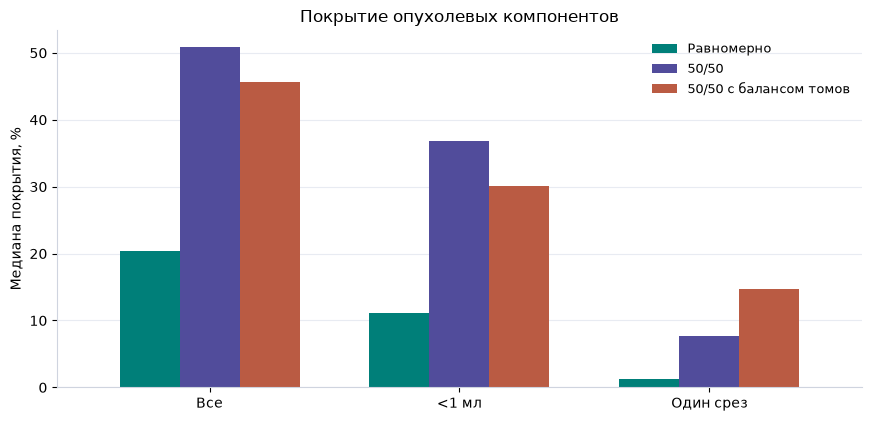

In [60]:
if not sampling_coverage.empty:
    coverage = sampling_coverage.pivot(index="group", columns="method", values="median_pct")
    groups = [group for group in ["Все", "<1 мл", "Один срез"] if group in coverage.index]
    methods = ["Равномерно", "50/50", "50/50 с балансом томов"]
    coverage = coverage.loc[groups, methods]
    fig, ax = plt.subplots(figsize=(8.6, 4.1), layout="constrained")
    coverage.plot.bar(ax=ax, color=[test_color, train_color, tumor_color], width=0.72, rot=0)
    ax.set(title="Покрытие опухолевых компонентов", xlabel="", ylabel="Медиана покрытия, %")
    ax.legend(frameon=False, fontsize=9)
    style_plot(ax)
    plt.show()

Обычный 50/50 покрывает больше компонентов в целом и больше компонентов меньше 1 мл. Баланс по томам лучше покрывает компоненты на одном срезе, хотя положительных срезов в обоих вариантах поровну. Это покрытие разметки при отборе.

## Что берем в первый эксперимент

### Разбиение на фолды

Делим по целым КТ, чтобы срезы одного тома не попали одновременно в обучение и проверку. В каждом фолде стараемся оставить КТ без опухолевой метки и с малым числом размеченных срезов. Разбиение фиксируем после сверки геометрии и используем для всех сравнений.

In [61]:
def make_case_folds(profiles, components, n_folds=5):
    folds = profiles[["case", "tumor_slices", "z_mm"]].sort_values("case").reset_index(drop=True)
    max_component_ml = components.groupby("case")["volume_ml"].max()
    folds["no_tumor"] = folds["tumor_slices"] == 0
    folds["few_tumor_slices"] = folds["tumor_slices"].between(1, 5)
    folds["only_small"] = folds["case"].map(max_component_ml).lt(1)
    folds["z_ge_3_mm"] = folds["z_mm"] >= 3
    folds["stratum"] = np.select(
        [folds["no_tumor"], folds["few_tumor_slices"], folds["only_small"]],
        ["Без опухолевой метки", "1-5 срезов с опухолью", "Только компоненты <1 мл"],
        default="Остальные",
    )
    folds["fold"] = 0
    rng = np.random.default_rng(42)
    offset = 0
    for _, group in folds.groupby("stratum", sort=True):
        indices = rng.permutation(group.index)
        folds.loc[indices, "fold"] = 1 + (offset + np.arange(len(indices))) % n_folds
        offset += len(indices)
    return folds

### Состав фолдов

In [62]:
folds = pd.DataFrame()
fold_summary = pd.DataFrame()
if shared_names or ct_duplicates["split"].eq("train").any():
    raise ValueError("Найдены повторы КТ. Нужно проверить список томов для фолдов.")

if len(profiles) >= 5 and not inventory["missing"].any():
    folds = make_case_folds(profiles, components)
    fold_summary = folds.groupby("fold").agg(
        cases=("case", "size"), no_tumor=("no_tumor", "sum"),
        few_tumor_slices=("few_tumor_slices", "sum"),
        only_small=("only_small", "sum"), z_ge_3_mm=("z_ge_3_mm", "sum"),
    ).reset_index()
    display(fold_summary)

,fold,cases,no_tumor,few_tumor_slices,only_small,z_ge_3_mm
0,1,27,2,2,5,1
1,2,26,3,1,3,4
2,3,26,3,1,3,4
3,4,26,3,1,2,3
4,5,26,2,1,2,3


Во всех пяти фолдах есть КТ без опухолевой метки и КТ с небольшим числом размеченных срезов. Томы с большим шагом распределены менее равномерно. Если несколько КТ относятся к одному пациенту, перед обучением их нужно отнести к одному фолду.

### План сравнения

- Стартуем с сетки 0,8 × 0,8 × 1 мм, широкого окна HU и обычного отбора 50/50. Сначала сравниваем шаг по Z, не меняя архитектуру, фолды, окно и способ отбора.
- Затем на одной сетке сравниваем обычный 50/50 и 50/50 с балансом по томам при одинаковом бюджете обучения.
- Считаем Dice, долю найденных мелких компонентов и число ложных находок на КТ. Оцениваем на исходной разметке, исчезнувшие при ресемплинге компоненты не должны выпадать из оценки. КТ с большим исходным шагом смотрим отдельно.
- Test без открытых масок оставляем для сравнения характеристик снимков.

### Сохранение таблиц


In [63]:
output = Path("task03_eda")
output.mkdir(exist_ok=True)
dicom_names = ircad_comparison.set_index("case")["ircad"]
geometry_fixes = {
    case: {"ircad": dicom_names[case], "affine_ras_mm": grid.tolist()}
    for case, grid in corrected_grids.items()
}
with (output / "ircad_geometry.json").open("w", encoding="utf-8") as file:
    json.dump({"cases": geometry_fixes}, file, indent=2)

tables = {
    "inventory": inventory,
    "exclusion_summary": exclusion_summary,
    "excluded_train_labels": excluded_train,
    "cases": cases,
    "review": review,
    "train_clean": train_clean,
    "test_clean": test_clean,
    "correlations": correlations,
    "geometry": geometry,
    "ircad_comparison": ircad_comparison,
    "ircad_rejected": ircad_rejected,
    "volume_correlations": volume_corr.to_frame(),
    "contrast": contrast,
    "ct_duplicates": ct_duplicates.drop(columns="ct_hash"),
    "mask_quality": mask_qc.drop(columns="mask_hash", errors="ignore"),
    "ct_review_slices": ct_review_slices,
    "mask_profiles": profiles,
    "components": components,
    "mask_review": mask_review,
    "slice_sampling": sampling,
    "slice_sampling_coverage": sampling_coverage,
    "slice_sampling_runs": sampling_runs,
    "resampling_components": step_components,
    "resampling_summary": step_summary,
    "resampling_losses": total_losses,
    "resampling_cases": resampling_cases,
    "resampling_sensitivity": loss_sensitivity,
}
if not folds.empty:
    tables["folds_candidate"] = folds
    tables["fold_coverage"] = fold_summary

for name, table in tables.items():
    keep_index = name in (
        "correlations", "exclusion_summary", "volume_correlations", "resampling_summary", "resampling_losses",
    )
    table.to_csv(output / f"{name}.csv", index=keep_index)